## SDR for Classification Datasets

In this notebook, we will look at using the SDR method for building target-aware prototypes for the COIL-20 dataset.

In [1]:
# Allow importing from the parent directory
import sys

sys.path.append("..")

In [2]:
def normalize(X):
    """
    Normalizes the input tensor X by subtracting the mean and
    dividing by the standard deviation along the first dimension (rows).
    """
    mean = X.mean(0, keepdim=True)
    std = X.std(0, keepdim=True)
    return (X - mean) / std

In [3]:
import matplotlib.pyplot as plt
import torch

torch.set_default_dtype(torch.double)

seed = 0

# Load the COIL-20 dataset
data = torch.load("../data/coil20_50d.pt")
X, y = data["X"].numpy(), data["y"].numpy()

X, y = normalize(torch.tensor(X)), torch.tensor(y)

In [4]:
from src.sdr import SDR
from src.affinities import (
    NormalizedGaussianAndStudentAffinity,
    SymmetricEntropicAffinity,
)

# Initialize the SDR method with SEA for the data affinity and Student-t for the embedding affinity
dr = SDR(
    affinity_data=SymmetricEntropicAffinity(perp=20, lr=0.1),
    affinity_embedding=NormalizedGaussianAndStudentAffinity(student=True),
    hsic_kernel_z="rq",
    hsic_kernel_y="delta",
    fgw_loss="ce_loss",
    loss_fun="kl_loss",
    objective="sdr",
    alpha=0.2,
    output_sam=100,
    output_dim=2,
    max_iter_outer=20,
    tol=1e-5,
    lambda_hsic=1000.0,
)

Z, L = dr.fit_transform(X, y)

---------- Computing the symmetric entropic affinity matrix ----------


perps :  1.994e+01 +- 3.214e-01, marginal :  1.001e+00 +- 4.214e-03: 100%|██████████| 500/500 [00:02<00:00, 166.92it/s]


---------- Warning: max iter attained, algorithm stops but may not have converged ----------


/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distributional-reduction-BVcFI9L--py3.12/lib/python3.12/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/saiaakashramesh/Library/Caches/pypoetry/virtualenvs/distribu

--- 0-th outer loop ---


...

---------- delta loss convergence ----------
--- 2-th outer loop ---


Loss :  1.063e+03, struct :  8.482e+03, sup :  6.333e-01, delta :  1.699e-05 :   8%|▊         | 82/1000 [00:00<00:04, 218.63it/s]


---------- delta loss convergence ----------
--- 3-th outer loop ---


Loss :  1.063e+03, struct :  8.483e+03, sup :  6.334e-01, delta :  6.688e-05 :   0%|          | 4/1000 [00:00<00:05, 182.51it/s]


---------- delta loss convergence ----------
--- Breaking : BCD iteration increasing the loss ---


In [5]:
from src.hsic_loss import hsic

# Compute the HSIC values for the original data and the reduced data for comparison
cka_X_train = hsic(
    X,
    y,
    kernel_z="rq",
    kernel_y="delta",
)
cka_Z_train = hsic(Z, y, kernel_z="rq", kernel_y="delta", T=dr.T)

print(f"HSIC(X_train, Y) = {cka_X_train:.4f}")
print(f"HSIC(Z_train, Y) = {cka_Z_train:.4f}")

HSIC(X_train, Y) = 0.5192
HSIC(Z_train, Y) = 0.6335


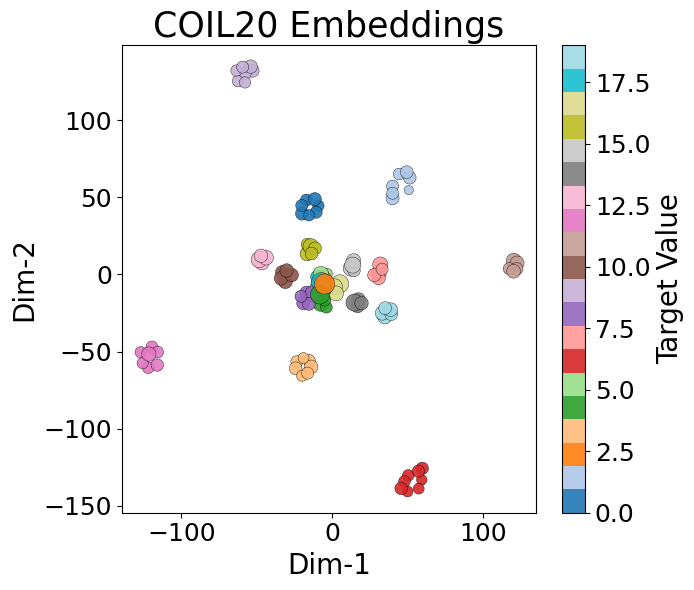

In [6]:
from src.utils import plan_color

# Set font sizes for the plot
TITLE_FONT_SIZE = 25
AXIS_LABEL_FONT_SIZE = 20
TICK_FONT_SIZE = 18
LABEL_FONT_SIZE = 20

proto_labels, proto_sizes = plan_color(dr.T, y.long())

# Plot the 2D embeddings with color-coded labels and size-coded prototypes
plt.figure(figsize=(7, 6))
plt.scatter(
    Z[:, 0].detach().cpu(),
    Z[:, 1].detach().cpu(),
    c=proto_labels.detach().cpu(),
    s=30 + 200 * (proto_sizes.detach().cpu() / proto_sizes.max().detach().cpu()),
    cmap="tab20",
    alpha=0.9,
    edgecolors="k",
    linewidths=0.3,
)
plt.tick_params(axis="both", which="both", labelsize=TICK_FONT_SIZE)
plt.xlabel("Dim-1", fontsize=AXIS_LABEL_FONT_SIZE)
plt.ylabel("Dim-2", fontsize=AXIS_LABEL_FONT_SIZE)
cbar = plt.colorbar(label="Target Value")
cbar.ax.tick_params(labelsize=TICK_FONT_SIZE)
cbar.set_label("Target Value", fontsize=LABEL_FONT_SIZE)
plt.title("COIL20 Embeddings", fontsize=TITLE_FONT_SIZE)
# plt.show()
plt.tight_layout()

In [9]:
from src.scores import scores_clustdr

# Compute clustering and classification scores for the reduced data
scores = scores_clustdr(
    dr.T,
    Z,
    y,
    X,
    score_list=[
        "hom",
        "nmi",
        "kmeans",
        "sil",
    ],
)
print("SDR:", scores)

--- Z: torch.Size([100, 2]) ---
SDR: {'hom': 99.71, 'nmi': 99.71, 'kmeans': 92.5, 'sil': 58.68}
